In [ ]:
# This should install any required dependencies assuming JAX has already been installed
# See https://jax.readthedocs.io/en/latest/installation.html for details on installing JAX for your system
try:
    import luas
except ImportError:
    !git clone https://github.com/markfortune/luas.git
    %cd luas
    %pip install .
    %cd ..

try:
    import jaxoplanet
except ImportError:
    %pip install -q jaxoplanet

try:
    import numpyro
except ImportError:
    %pip install -q numpyro
    
try:
    import corner
except ImportError:
    %pip install -q corner
    
try:
    import arviz as az
except ImportError:
    %pip install -q arviz

(numpyro_example)=

# NumPyro Example: Transmission Spectroscopy

*NOTE: This tutorial notebook is currently in development. Expect significant changes in the future*

This notebook provides to tutorial on how to use ``NumPyro`` to perform spectroscopic transit light curve fitting. We will first go through how to generate transit light curves in ``jax``, then we will create synthetic noise which will be correlated in both wavelength and time. Finally we will use ``NumPyro`` to fit the noise contaminated light curves and recover the input transmission spectrum. You can run this notebook yourself on Google Colab by clicking the rocket icon in the top right corner.

``NumPyro`` has the advantage of being written in ``jax`` which makes implementing some things with ``luas`` like parallelisation simpler compared to ``PyMC``. However, arguably it is less user-friendly than ``PyMC`` and has less flexibility at times. For example, unlike ``PyMC`` blocked Gibbs sampling is difficult to implement in ``NumPyro`` (at least at the time of writing this).

If you have a GPU available (including a GPU on Google Colab) then ``jax`` should detect this and run on it automatically. Running ``jax.devices()`` tells us what ``jax`` has found to run on. If there is a GPU available but it is not detected this could indicate ``jax`` has not been correctly installed for GPU. Also note if running on Google Colab that the T4 GPUs have poor performance at double precision floating point and may not show significant speed-ups, while more modern hardware such as NVIDIA Tesla V100s or better tend to show significant performance improvements

In [2]:
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import os.path
import jaxoplanet
import arviz as az
import pandas as pd
import luas
import numpyro
import corner
import logging
from astropy.constants import M_sun, R_sun, G
import astropy.units as u

# Useful to set when looking at retrieved values for many parameters
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# This helps give more information on what NumPyro is doing during inference
logging.getLogger().setLevel(logging.INFO)

# Running this at the start of the runtime ensures jax uses 64-bit floating point numbers
# as jax uses 32-bit by default
jax.config.update("jax_enable_x64", True)

# This will list available CPUs/GPUs JAX is picking up
print("Available devices:", jax.devices())

# This can be commented out to allow NumPyro to run parallel chains on CPU but it may or may not improve performance
# numpyro.set_host_device_count(2)

Available devices: [CpuDevice(id=0)]


First we will use [jaxoplanet](https://github.com/exoplanet-dev/jaxoplanet) which has its own documentation and tutorials [here](https://jax.exoplanet.codes/en/latest/). Let's create a single light curve with quadratic limb darkening. We will use the ``transit_light_curve`` function from ``luas.exoplanet`` which we have included below to show what it does.

Note, parameters which will be shared between light curves are assumed to be size-1 arrays here, this makes things easier to implement with ``jax.vmap`` and ``PyMC`` and is done here for ``NumPyro`` for consistency.

In [3]:
# Calculates solar density in kg/m^3 to convert between fitting for stellar density or a/R*
solar_density = ((M_sun/R_sun**3)/(u.kg/u.m**3)).si
def transit_light_curve(par, t):
    """Uses the package `jaxoplanet <https://github.com/exoplanet-dev/jaxoplanet>`_ to calculate
    transit light curves using JAX assuming quadratic limb darkening and a simple circular orbit.
    
    Note:
        If using this function then make sure to cite jaxoplanet separately as it is an independent
        package from luas.
    
    This particular function will only compute a single transit light curve but JAX's vmap function
    can be used to calculate the transit light curve of multiple wavelength bands at once.
    
    It assumes that the central transit time `T0`, period `P`, semi-major axis to stellar ratio a/R* = `a`
    and impact parameter `b` are size-1 arrays as this makes it easier to implement with vmap
    and PyMC. Feel free to vary this however, for example it can easily be modified to fit for T0 separately
    for each light curve.
    
    .. code-block:: python

        >>> from luas.exoplanet import transit_light_curve
        >>> import jax.numpy as jnp
        >>> par = {
        >>> ... "T0":0.*jnp.ones(1),     # Central transit time (days)
        >>> ... "P":3.4*jnp.ones(1),     # Period (days)
        >>> ... "a":8.2*jnp.ones(1),     # Semi-major axis to stellar ratio (aka a/R*)
        >>> ... "rho":0.1,               # Radius ratio (aka Rp/R* or rho)
        >>> ... "b":0.5*jnp.ones(1),     # Impact parameter
        >>> ... # Uses standard quadratic limb darkening parameterisation:
        >>> ... # I(r) = 1 − u1(1 − mu) − u2(1 − mu)^2
        >>> ... "u1":0.5,                # First quadratic limb darkening coefficient
        >>> ... "u2":0.1,                # Second quadratic limb darkening coefficient
        >>> ... "Foot":1.,               # Baseline flux out of transit
        >>> ... "Tgrad":0.               # Gradient in baseline flux (hrs^-1)
        >>> }
        >>> t = jnp.linspace(-0.1, 0.1, 100)
        >>> flux = transit_light_curve(par, t)
    
    Args:
        par (PyTree): The transit parameters stored in a PyTree/dictionary (see example above).
        t (JAXArray): Array of times to calculate the light curve at.
            
    Returns:
        JAXArray: Array of flux values for each time input.
        
    """

    # Calculates stellar density in kg/m^3 using par["a"] = a/R*
    # Can modify this function to explicitly fit for the stellar density if desired
    rho_s = 3*jnp.pi*par["a"][0]**3/(G.value*(par["P"][0]*86400)**2)

    # Creates an object describing the star
    # This code actually sets the stellar radius as 1 solar radius
    # It gives the density relative to solar density
    # This actually gives a different mass for the central star but this does not affect the transit model
    # It effectively just creates an analogous system scaled in distance by a factor R_sun/R*
    # This avoids having to input a value for R* which is irrelevant for transit calculations
    # This does not affect a/R*, Rp/R* or b as they are all dimensionless quantities
    central = jaxoplanet.orbits.keplerian.Central(density=rho_s/solar_density,radius=1.)

    # Define the planetary body
    body = jaxoplanet.orbits.keplerian.Body(
        period=par["P"][0],
        time_transit=par["T0"][0],
        radius=par["rho"],
        impact_param=par["b"][0],
        eccentricity=0., # Can optionally include eccenticity here
        omega_peri = 0.,
    )

    # Creates an orbit object with both the central `star` object and the `body` planet object
    orbit = jaxoplanet.orbits.keplerian.OrbitalBody(central = central, body = body)

    # Define light curve function `lc` using the quadratic limb darkening coefficients u1 and u2
    lc = jaxoplanet.light_curves.limb_dark.light_curve(orbit, [par["u1"], par["u2"]])

    # Calculates the transit light curve flux dip with a baseline of one (default from jaxoplanet is zero)
    flux = 1 + lc(t)

    # Scales the transit model with a linear baseline
    baseline = par["Foot"] + 24*par["Tgrad"]*(t - par["T0"][0])
    
    return baseline*flux

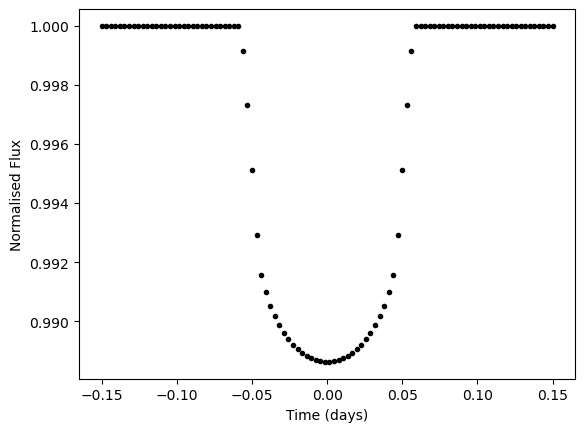

In [4]:
# Use some simple parameters typical of a hot Jupiter
# Note the size-1 arrays on parameters which will later be shared between light curves
mfp = {
    "T0":0.*jnp.ones(1),     # Central transit time
    "P":3.*jnp.ones(1),      # Period (days)
    "a":8.*jnp.ones(1),      # Semi-major axis to stellar ratio aka a/R*
    "rho":0.1,               # Radius ratio rho aka Rp/R*
    "b":0.5*jnp.ones(1),     # Impact parameter
    "u1":0.5,                # First quadratic limb darkening coefficient
    "u2":0.1,                # Second quadratic limb darkening coefficient
    "Foot":1.,               # Baseline flux out of transit
    "Tgrad":0.               # Gradient in baseline flux (hrs^-1)
}

# Generate 100 evenly spaced time points (in units of days)
N_t = 100
x_t = jnp.linspace(-0.15, 0.15, N_t)

plt.plot(x_t, transit_light_curve(mfp, x_t), "k.")
plt.xlabel("Time (days)")
plt.ylabel("Normalised Flux")
plt.show()

Now we want to take our ``jax`` function which has been written to generate a 1D light curve in time and instead create separate light curves in each wavelength. We also will want to share some parameters between light curves (e.g. impact parameter b, system scale a/Rs) while varying other parameters for each wavelength (e.g. radius ratio Rp/Rs).

We could of course write a ``for`` loop but ``for`` loops can be slow to compile with ``jax``. A more efficient option is to make use of the ``jax.vmap`` function which allows us to "vectorise" our function from 1D to 2D:

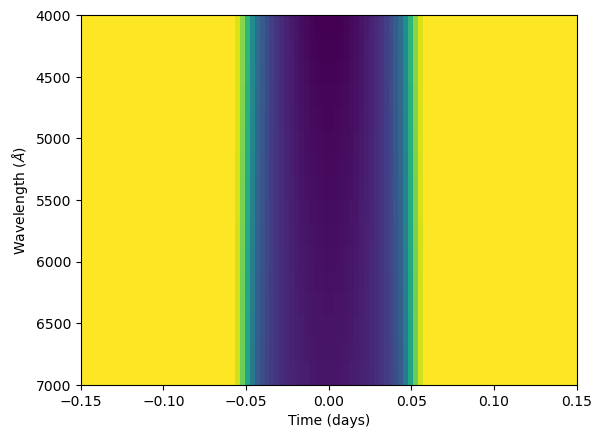

In [5]:
# First we must tell JAX which parameters of the function we want to vary for each light curve
# and which we want to be shared between light curves
transit_light_curve_vmap = jax.vmap(
    # First argument is the function to vectorise
    transit_light_curve, 
    
    # Specify which parameters to share and which to vary for each light curve
    in_axes=(
        {
        # If a parameter is to be shared across each light curve then it should be set to None
        "T0":None, "P":None, "a":None, "b":None,

        # Parameters which vary in wavelength are given the dimension of the array to expand along
        # In this case we are expanding from 0D arrays to 1D arrays so this must be 0
        "rho":0, "u1":0, "u2":0, "Foot":0, "Tgrad":0
        },
        # Also must specify that we will share the time array (the second function parameter)
        # between light curves
         None,  
    ),
    
    # Specify the output dimension to expand along, this will default to 0 anyway
    # Will output extra flux values for each light curve as additional rows
    out_axes = 0,
)

# Let's define a wavelength range of our data, this isn't actually used by our mean function
# but we will use it for defining correlation in wavelength later
N_l = 16 # Feel free to vary the number of light curves, even >100 light curves may perform quite efficiently
x_l = np.linspace(4000, 7000, N_l)

# Now we define our 2D transit parameters, let's just assume most parameters are constant in wavelength
# We are letting the limb darkening parameters vary linearly in wavelength, feel free to replace
# with generated limb-darkening parameters from a package of your choice
# Note we are now
mfp_2D = {
    "T0":0.*jnp.ones(1),                         # Central transit time
    "P":3.*jnp.ones(1),                         # Period (days)
    "a":8.*jnp.ones(1),                          # Semi-major axis to stellar ratio aka a/R*
    "rho":0.1*jnp.ones(N_l),          # Radius ratio rho aka Rp/R*
    "b":0.5*jnp.ones(1),                         # Impact parameter
    "u1":jnp.linspace(0.7, 0.4, N_l), # First quadratic limb darkening coefficient
    "u2":jnp.linspace(0.1, 0.2, N_l), # Second quadratic limb darkening coefficient
    "Foot":1.*jnp.ones(N_l),          # Baseline flux out of transit
    "Tgrad":0.*jnp.ones(N_l)          # Gradient in baseline flux (days^-1)
}

# Call our new vmap of transit_light_curve to simultaneously compute light curves for all wavelengths
transit_model_2D = transit_light_curve_vmap(mfp_2D, x_t)

# Visualise the transit light curves
plt.imshow(transit_model_2D, aspect = 'auto', extent = [x_t[0], x_t[-1], x_l[-1], x_l[0]])
plt.xlabel("Time (days)")
plt.ylabel(r"Wavelength ($\AA$)")
plt.show()

The form of a mean function with ``luas.GP`` is ``f(par, x_l, x_t)`` where ``par`` is a PyTree, ``x_l`` is a JAXArray of inputs that lie along the wavelength/vertical dimension of the data (e.g. an array of wavelength values) and ``x_t`` is a JAXArray of inputs that lie along the time/horizontal dimension (e.g. an array of timestamps). Our transit model does not require wavelength values to be computed but we still write our wrapper function to be of this form.

We will also switch to the [Kipping (2013)](https://arxiv.org/abs/1308.0009) limb darkening parameterisation as it makes it easier to place simple bounds on these parameters and has the benefit of placing a uniform prior on the physically allowed space of limb darkening parameters.

Also feel free to use the ``luas.exoplanet.transit_2D`` function instead which is similar to the below function with the exception that it fits for transit depth $d = \rho^2$ instead of radius ratio $\rho$

In [6]:
from luas.exoplanet import ld_to_kipping, ld_from_kipping

def transit_light_curve_2D(p, x_l, x_t):
    
    # vmap requires that we only input the parameters which have been explicitly defined how they vectorise
    transit_params = ["T0", "P", "a", "rho", "b", "Foot", "Tgrad"]
    mfp = {k:p[k] for k in transit_params}
    
    # Calculate limb darkening coefficients from the Kipping (2013) parameterisation.
    mfp["u1"], mfp["u2"] = ld_from_kipping(p["q1"], p["q2"])
    
    # Use the vmap of transit_light_curve to calculate a 2D array of shape (M, N) of flux values
    # For M wavelengths and N time points.
    return transit_light_curve_vmap(mfp, x_t)

# Switch to Kipping parameterisation
if "u1" in mfp_2D:
    mfp_2D["q1"], mfp_2D["q2"] = ld_to_kipping(mfp_2D["u1"], mfp_2D["u2"])
    del mfp_2D["u1"]
    del mfp_2D["u2"]

# This should produce the same result as transit_light_curve_vmap as we have only changed the limb darkening parameterisation
M = transit_light_curve_2D(mfp_2D, x_l, x_t)

Now that we have our mean function created, it's time to start building a kernel function. We will try keep things simple and use a squared exponential kernel for correlation in both time and wavelength, and white noise which varies in amplitude between different light curves.

$$
\begin{equation}
\mathbf{K}_{ij} = h^2 \exp\left(-\frac{|\lambda_i - \lambda_j|^2}{2 l_\mathrm{\lambda}^2}\right) \exp\left(-\frac{|t_i - t_j|^2}{2 l_{t}^2}\right) + \sigma_{\lambda_i}^2\delta_{\lambda_i \lambda_j} \delta_{t_i t_j}
\end{equation}
$$

This kernel contains a correlated noise component with height scale $h$, length scale in wavelength $l_\mathrm{\lambda}$ and length scale in time $l_t$. There is also a white noise term which can have different white noise amplitudes at different wavelengths.

We will need to write this kernel as separate wavelength and time kernel functions multiplied together satisfying:

$$
\begin{equation}
\text{K}(\Delta \lambda, \Delta t) = \text{K}_{l}(\Delta \lambda) \otimes \text{K}_{t}(\Delta t) + \text{S}_{l}(\Delta \lambda) \otimes \text{S}_{t}(\Delta t)
\end{equation}
$$

We can do this by choosing the equations below for our kernel functions which generate each component matrix.

$$
\begin{equation}
    \text{K}_l(\lambda_i, \lambda_j) = h^2 \exp\left(-\frac{|\lambda_i - \lambda_j|^2}{2 l_\mathrm{\lambda}^2}\right) 
\end{equation}
$$

$$
\begin{equation}
    \text{K}_t(t_i, t_j) = \exp\left(-\frac{|t_i - t_j|^2}{2 l_{t}^2}\right)
\end{equation}
$$

$$
\begin{equation}
    \text{S}_l(\lambda_i, \lambda_j) = \sigma_{\lambda_i}^2\delta_{\lambda_i \lambda_j}
\end{equation}
$$

$$
\begin{equation}
    \text{S}_t(t_i, t_j) = \delta_{t_i t_j}
\end{equation}
$$

Note that for numerical stability reasons it's important that the $S_l$ and $S_t$ matrices are well-conditioned (i.e. can be stably inverted) while $K_l$ and $K_t$ do not need to be well-conditioned (or even invertible), semi-positive definite matrices are okay for these. The matrices which contain values added along the diagonal should be well-conditioned as this "regularises" the matrices, while a squared exponential kernel with nothing added along the diagonal is unlikely to be well-conditioned.

In [7]:
from luas import kernels
from luas import LuasKernel, GeneralKernel

# We implement each of these kernel functions below using the luas.kernels module
# for an implementation of the squared exponential kernel

# The wavelength kernel functions take the wavelength regression variable(s) x_l as input (of shape (N_l) or (d_l, N_l))
def Kl_fn(hp, x_l1, x_l2, wn = True):
    Kl = jnp.exp(2*hp["log_h"])*kernels.squared_exp(x_l1, x_l2, jnp.exp(hp["log_l_l"]))
    return Kl

# The time kernel functions take the time regression variable(s) x_t as input (of shape (N_t) or (d_t, N_t))
def Kt_fn(hp, x_t1, x_t2, wn = True):
    return kernels.squared_exp(x_t1, x_t2, jnp.exp(hp["log_l_t"]))

# For both the Sl and St functions we set a decomp attribute to "diag" because they produce diagonal matrices
# This speeds up the log likelihood calculations as it tells luas these matrices are easy to eigendecompose
# But don't do this for the Kl and Kt functions even if they produce diagonal matrices unless you know what you are doing
# This is because you are telling luas that the transformations of Kl and Kt are diagonal, not Kl and Kt themselves

# If the wn keyword argument is True then white noise should be included (doesn't affect most matrices)
# This is used by gp.predict when performing Gaussian process prediction
# Note it does not matter that Sl is not invertible without white noise
def Sl_fn(hp, x_l1, x_l2, wn = True):
    Sl = jnp.zeros((x_l1.shape[-1], x_l2.shape[-1]))
    
    if wn:
        # If we are including white noise then safe to assume Sl is a square matrix for any calculations in luas.GP
        Sl += jnp.diag(jnp.exp(2*hp["log_sigma"])) # Assumes hp["log_sigma"] is an array of size N_l

    return Sl
Sl_fn.decomp = "diag" # Sl is a diagonal matrix

def St_fn(p, x_t1, x_t2, wn = True):
    return jnp.eye(x_t1.shape[-1])
St_fn.decomp = "diag" # St is a diagonal matrix

# Build a LuasKernel object using these component kernel functions
# The full covariance matrix applied to the data will be K = Kl KRON Kt + Sl KRON St
kernel = LuasKernel(Kl = Kl_fn, Kt = Kt_fn, Sl = Sl_fn, St = St_fn,
                    
                    # Can select whether to use previously calculated eigendecompositions when running MCMC
                    # Performs an additional check in each step to see if each component covariance matrix has changed since last step
                    # Useful when doing blocked Gibbs or if fixing some hyperparameters
                    use_stored_values = True, 
                   )

# We can also create a kernel object with the same kernel as LuasKernel but without the kronecker product optimisations
# We will use this to show they produce the same answers and to compare runtimes
# While it does take the LuasKernel.K function, this simply takes Kl_fn, Kt_fn, Sl_fn and St_fn and kronecker products the results together
# So it builds the same covariance matrix but the log likelihood calculations are completely different
general_kernel = GeneralKernel(K = kernel.K)

The ``LuasKernel.visualise_covariance_matrix`` method should be a useful way of visualising each of the four component matrices and ensure everything you have written looks right. It uses ``matplotlib.pyplot.pcolormesh`` to visualise the covariance matrices which can produce weird looking plots for large matrices however.

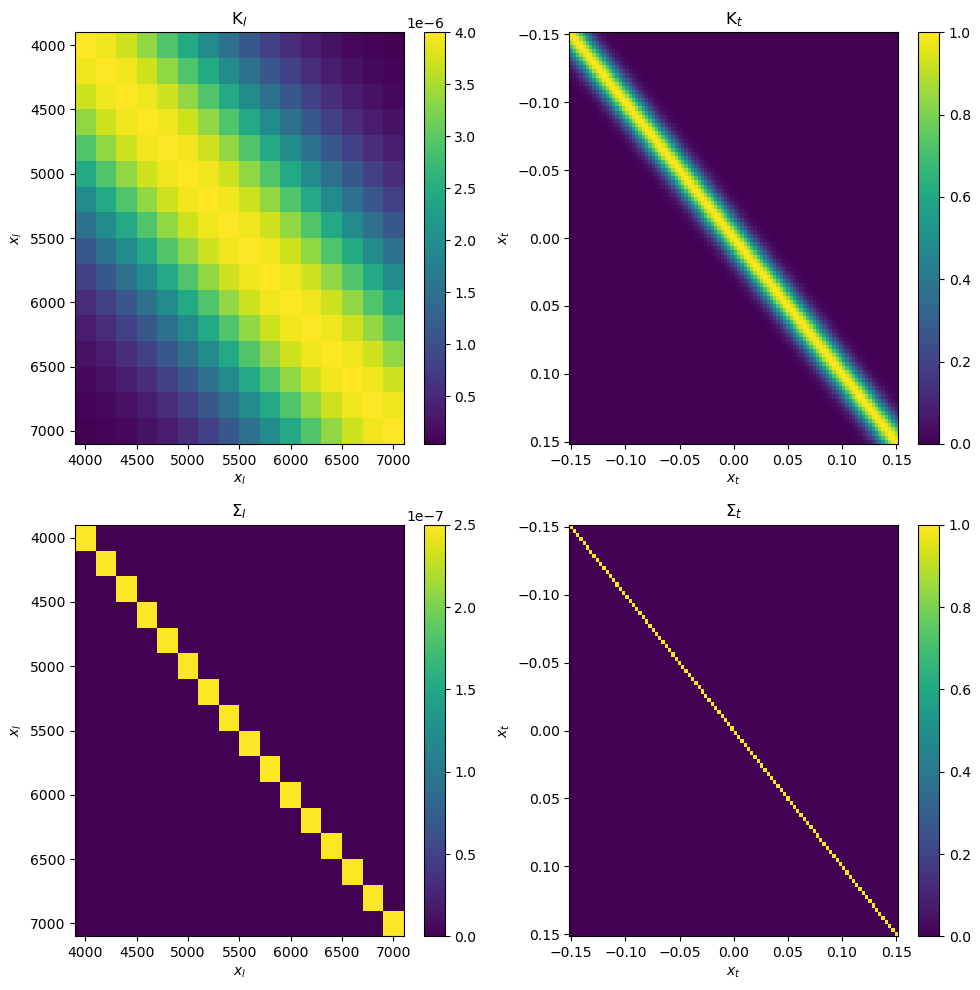

In [8]:
# Some sample hyperparameters
hp = {
    "log_h":jnp.log(2e-3),    # log height scale of correlated noise
    "log_l_l":jnp.log(1000.), # log wavelength length scale
    "log_l_t":jnp.log(0.011), # log time length scale
    "log_sigma":jnp.log(5e-4)*jnp.ones(N_l), # white noise amplitude at each wavelength
}

kernel.visualise_covariance_matrix(hp, x_l, x_t);

We can test the numerical stability of both the ``LuasKernel`` and ``GeneralKernel`` with a simple test where we multiply a random normal vector by the inverse of the covariance matrix followed by multiplying by the covariance matrix. This should result in the original random normal vector we started with. We should expect some level of floating point errors but they are likely to be negligible relative to the noise level in a dataset. So far I have yet to see the ``LuasKernel`` perform poorly for any valid covariance matrix. If having issues here it is worth making sure that each covariance matrix generates a symmetric covariance matrix and that $S_l$ and $S_t$ are invertible.

In [9]:
# Generate a random normal vector
random_vec = np.random.normal(size = (N_l, N_t))

# Calculate alpha = K_inv @ random_vec
alpha = kernel.K_inv_by_vec(hp, x_l, x_t, random_vec)

# Calculate K @ alpha which should equal random_vec
K_K_inv_random_vec = kernel.K_by_vec(hp, x_l, x_t, alpha)

# Calculate the numerical errors from the original vector
calc_err = random_vec - K_K_inv_random_vec
print(f"Largest deviations (LuasKernel): {calc_err.min()}, {calc_err.max()}")

# Perform the same calculation with the general_kernel which builds the full covariance matrix
# and uses Cholesky decomposition for inverting the covariance matrix
K_inv_random_vec = general_kernel.K_inv_by_vec(hp, x_l, x_t, random_vec)
K_K_inv_random_vec = general_kernel.K_by_vec(hp, x_l, x_t, K_inv_random_vec)

calc_err = random_vec - K_K_inv_random_vec
print(f"Largest deviations (GeneralKernel): {calc_err.min()}, {calc_err.max()}")

Largest deviations (LuasKernel): -3.1086244689504383e-13, 2.7586266604373577e-13
Largest deviations (GeneralKernel): -3.2940317140628395e-13, 3.299582829185965e-13


Take a random noise draw from this covariance matrix. Try playing around with these values to see the effect varying each parameter has on the noise generated.

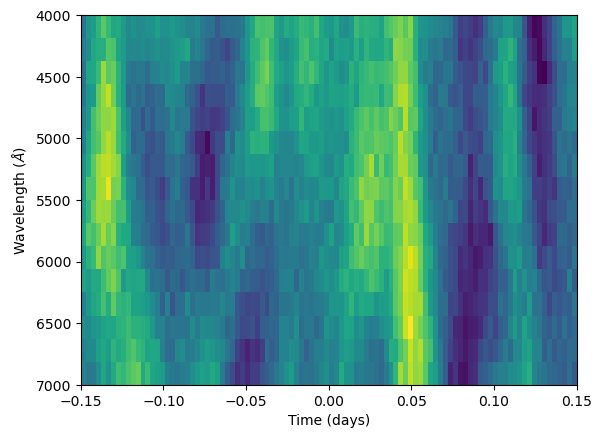

In [10]:
hp = {"log_h":jnp.log(2e-3), "log_l_l":jnp.log(1000.), "log_l_t":jnp.log(0.011),
      "log_sigma":jnp.log(5e-4)*jnp.ones(N_l),}

sim_noise = kernel.generate_noise(hp, x_l, x_t)

plt.imshow(sim_noise, aspect = 'auto', extent = [x_t[0], x_t[-1], x_l[-1], x_l[0]])
plt.xlabel("Time (days)")
plt.ylabel(r"Wavelength ($\AA$)")
plt.show()

Combining our light curves and noise model we can generate synthetic light curves contaminated by systematics correlated in time and wavelength

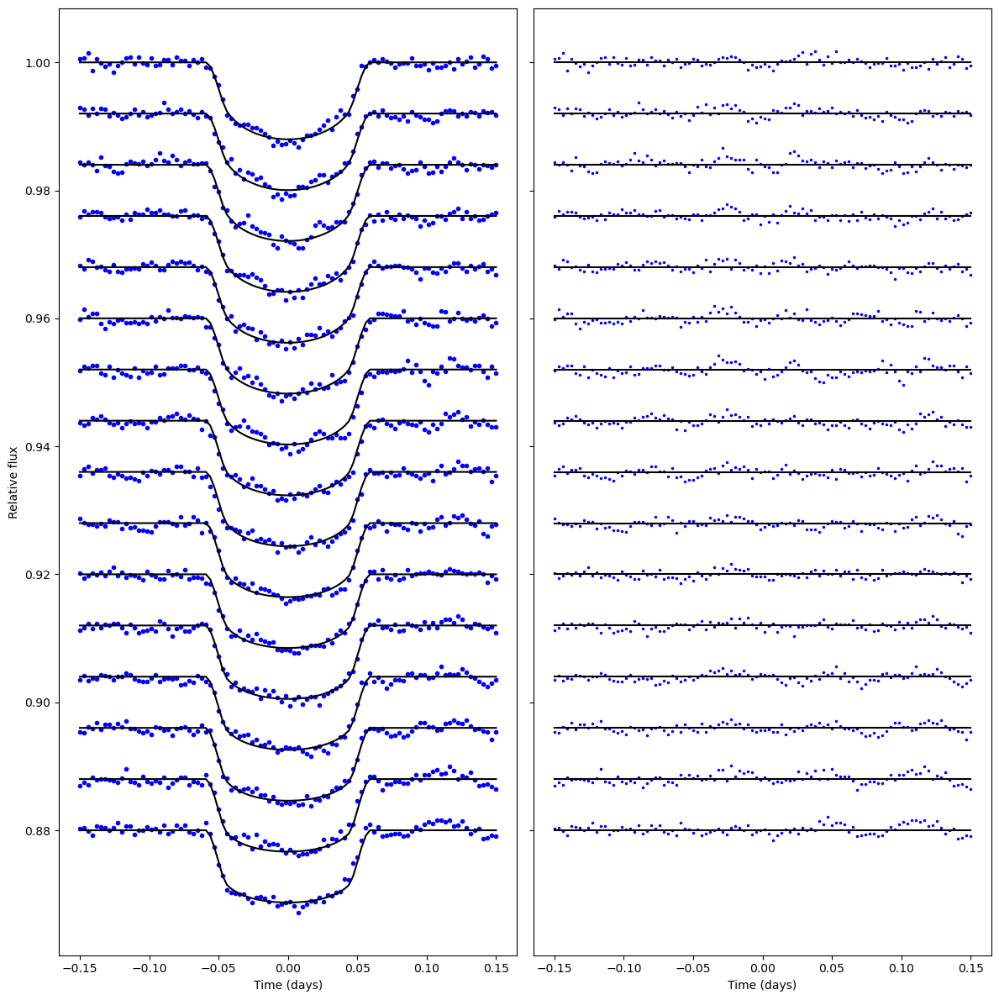

In [25]:
def plot_lightcurves(x_t, M, Y, sep = 0.008):
    """Quick function to visualise light curves and the residuals after subtraction of transit model
    
    """
    N_l = x_l.shape[-1]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 12), sharey = True)
    for i in range(N_l):
        ax1.plot(x_t, Y[i, :] + np.arange(0, -sep*N_l, -sep)[i], 'bo', ms = 3)
        
        ax1.plot(x_t, M[i, :] + np.arange(0, -sep*N_l, -sep)[i], 'k-', ms = 3)
        ax2.plot(x_t, Y[i, :] - M[i, :] + np.arange(1, 1-sep*N_l, -sep)[i], 'b.', ms = 3)
        ax2.plot(x_t, np.arange(1, 1-sep*N_l, -sep)[i]*np.ones_like(x_t), 'k-', ms = 3)
    ax1.set_xlabel("Time (days)")
    ax2.set_xlabel("Time (days)")
    ax1.set_ylabel("Relative flux")
    plt.tight_layout()

u1_sim, u2_sim = jnp.linspace(0.7, 0.4, N_l), jnp.linspace(0.1, 0.2, N_l)
q1_sim, q2_sim = ld_to_kipping(u1_sim, u2_sim)

# All parameters used to generate the synthetic data set with noise
p_sim = {
    # Mean function parameters
    "T0":0.*jnp.ones(1),                      # Central transit time
    "P":3.*jnp.ones(1),                       # Period (days)
    "a":8.*jnp.ones(1),                       # Semi-major axis to stellar ratio aka a/R*
    "rho":0.1*jnp.ones(N_l),                  # Radius ratio rho aka Rp/R* for each wavelength
    "b":0.5*jnp.ones(1),                      # Impact parameter
    "q1":q1_sim,                              # First quadratic limb darkening coefficient for each wavelength
    "q2":q2_sim,                              # Second quadratic limb darkening coefficient for each wavelength
    "Foot":1.*jnp.ones(N_l),                  # Baseline flux out of transit for each wavelength
    "Tgrad":0.*jnp.ones(N_l),                 # Gradient in baseline flux for each wavelength (days^-1)
    
    # Hyperparameters
    "log_h":jnp.log(5e-4)*jnp.ones(1),        # log height scale
    "log_l_l":jnp.log(1000.)*jnp.ones(1),     # log length scale in wavelength
    "log_l_t":jnp.log(0.011)*jnp.ones(1),     # log length scale in time
    "log_sigma":jnp.log(5e-4)*jnp.ones(N_l),  # log white noise amplitude for each wavelength
}

transit_signal = transit_light_curve_2D(p_sim, x_l, x_t)
sim_noise = kernel.generate_noise(p_sim, x_l, x_t)
Y = transit_signal*(1 + sim_noise)

plot_lightcurves(x_t, transit_signal, Y)

We may also want to define a logPrior function. While PyMC can also be used to define priors on parameters, it can be useful to let ``luas.GP`` handle non-uniform priors when it comes to MCMC tuning (as will be shown later).

The ``logPrior`` function input to ``luas.GP`` must be of the form ``logPrior(params)`` i.e. it may only take the PyTree of mean function parameters and hyperparameters as input.

In [12]:
# Places priors on the system scale and impact parameter
a_mean = p_sim["a"]
a_std = 0.1
b_mean = p_sim["b"]
b_std = 0.01

# Set some limb darkening priors, normally these might be generated from a package like LDTk
u1_mean = u1_sim
u1_std = 0.01
u2_mean = u2_sim
u2_std = 0.01

def logPrior(p):
    logPrior = -0.5*((p["a"] - a_mean)/a_std)**2
    logPrior += -0.5*((p["b"] - b_mean)/b_std)**2
    
    u1, u2 = ld_from_kipping(p["q1"], p["q2"])
    u1_priors = -0.5*((u1 - u1_mean)/u1_std)**2
    u2_priors = -0.5*((u2 - u2_mean)/u2_std)**2
    
    logPrior += u1_priors.sum() + u2_priors.sum()

    return logPrior.sum()

print("Log prior at simulated values:", logPrior(p_sim))

Log prior at simulated values: -1.5214846560659163e-28


We now have enough to define our ``luas.GP`` object and use it to try recover the original transmission signal injected into the correlated noise.

Starting log posterior value: 9780.791424303621


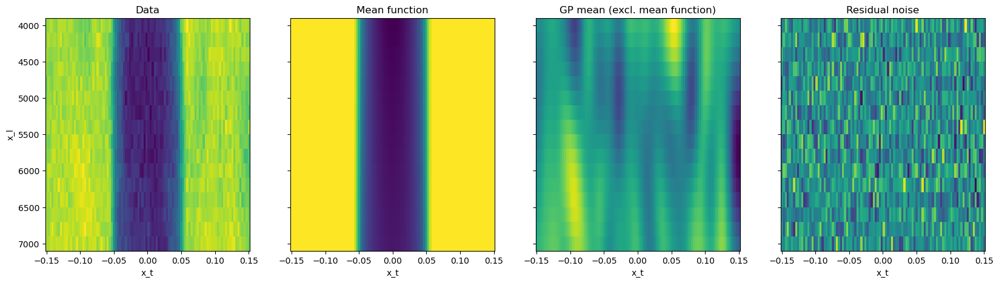

In [13]:
from luas import GP
from copy import deepcopy

# Initialise our GP object
# Make sure to include the mean function and log prior function if you're using them
gp = GP(kernel,  # Kernel object to use
        x_l,     # Regression variable(s) along wavelength/vertical dimension
        x_t,     # Regression variable(s) along time/horizontal dimension
        mf = transit_light_curve_2D,  # (optional) mean function to use, defaults to zeros
        logPrior = logPrior           # (optional) log prior function, defaults to zero
       )

# Initialise our starting values as the true simulated values
p_initial = deepcopy(p_sim)

# Convenient function for plotting the data and the GP fit to the data
gp.plot(p_initial, Y)
print("Starting log posterior value:", gp.logP(p_initial, Y))

Let's compare the runtime speed-up of using the optimisations in the ``LuasKernel``. Comparing runtimes with JAX is a little bit more involved than normal. First we want to pre-compile the functions using ``jax.jit`` so that we aren't timing how long each function takes to compile. We then must make sure we run the JIT-compiled functions once before benchmarking as the compilation step will be done based on the array sizes given in that first run. We then can time the JIT-compiled functions but make sure to include ``block_until_ready`` due to `jax` using [asynchronous dispatch](https://jax.readthedocs.io/en/latest/async_dispatch.html) (i.e. it waits until the calculation has actually finished).

Note that while the runtime improvement for this small data set may not be substantial, the methods have very different scaling with ``GeneralKernel.logP`` scaling as $\mathcal{O}(N_l^3 N_t^3)$ and ``LuasKernel.logP`` scaling as $\mathcal{O}(N_l^3 + N_t^3 + N_l N_t (N_l + N_t))$, so for larger data sets the difference may be much larger. ``GeneralKernel.logP`` may also crash for larger data sets due to its higher memory requirements.

In [14]:
# Create a similar GP object but using general Cholesky calculations in GeneralKernel instead of using LuasKernel
gp_general = GP(general_kernel,  # Kernel object to use
        x_l,     # Regression variable(s) along wavelength/vertical dimension
        x_t,     # Regression variable(s) along time/horizontal dimension
        mf = transit_light_curve_2D,  # (optional) mean function to use, defaults to zeros
        logPrior = logPrior           # (optional) log prior function, defaults to zero
       )

# Let's JIT compile each function before running (this should already be done in GP.py but is good practice anyway)
general_jit = jax.jit(gp_general.logP)
luas_jit = jax.jit(gp.logP)

# Run each calculation before benchmarking, note they should give the same answer up to floating point errors
print("GeneralKernel Calculation:", general_jit(p_initial, Y))
print("LuasKernel Calculation:", luas_jit(p_initial, Y))

# Benchmark each method
print("\nRuntime for GeneralKernel: ")
%timeit general_jit(p_initial, Y).block_until_ready()

print("Runtime for LuasKernel: ")
%timeit luas_jit(p_initial, Y).block_until_ready()

GeneralKernel Calculation: 9780.791424303628
LuasKernel Calculation: 9780.791424303621

Runtime for GeneralKernel: 
52.6 ms ± 13.4 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
Runtime for LuasKernel: 
2.41 ms ± 202 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


Now let's begin using ``NumPyro`` to perform a best-fit. We've set the true simulated values as our initial values so we should already be close to the optimal log posterior value but for real data this won't always be the case. Similar to the approach in Fortune et al. (2024), we will not be performing any white light curve analysis but instead will be joint-fitting all spectroscopic light curves simultaneously.

In [15]:
import numpyro
import numpyro.distributions as dist
from luas.numpyro_ext import LuasNumPyro
from copy import deepcopy

# Let's define some bounds
min_log_l_l = np.log(np.diff(x_l).min())
max_log_l_l = np.log(50*(x_l[-1] - x_l[0]))
min_log_l_t = np.log(np.diff(x_t).min())
max_log_l_t = np.log(3*(x_t[-1] - x_t[0]))

param_bounds = {
                # Bounds from Kipping (2013) at just between 0 and 1
                "q1":[jnp.array([0.]*N_l), jnp.array([1.]*N_l)],
                "q2":[jnp.array([0.]*N_l), jnp.array([1.]*N_l)],
    
                # Can optionally include bounds on other mean function parameters but often they will be well constrained by the data
                "rho":[jnp.array([0.]*N_l), jnp.array([1.]*N_l)],
    
                # Sometimes prior bounds on hyperparameters are important for sampling
                # However their choice can sometimes affect the results so use with caution
                "log_h":   [jnp.log(1e-6)*np.ones(1), jnp.log(1)*jnp.ones(1)],
                "log_l_l": [min_log_l_l*jnp.ones(1), max_log_l_l*jnp.ones(1)],
                "log_l_t": [min_log_l_t*jnp.ones(1), max_log_l_t*jnp.ones(1)],
                "log_sigma":[jnp.log(1e-6)*jnp.ones(N_l), jnp.log(1e-2)*jnp.ones(N_l)],
}

def transit_model(Y):
    # Makes of copy of any parameters to be kept fixed during sampling
    var_dict = deepcopy(p_initial)
    
    # Specify the parameters we've given bounds for
    var_dict["rho"] = numpyro.sample("rho", dist.Uniform(low = param_bounds["rho"][0],
                                                         high =param_bounds["rho"][1]))
    var_dict["log_h"] = numpyro.sample("log_h", dist.Uniform(low = param_bounds["log_h"][0],
                                                             high = param_bounds["log_h"][1]))
    var_dict["log_l_l"] = numpyro.sample("log_l_l", dist.Uniform(low = param_bounds["log_l_l"][0],
                                                                 high = param_bounds["log_l_l"][1]))
    var_dict["log_l_t"] = numpyro.sample("log_l_t", dist.Uniform(low = param_bounds["log_l_t"][0],
                                                                 high = param_bounds["log_l_t"][1]))
    var_dict["log_sigma"] = numpyro.sample("log_sigma", dist.Uniform(low = param_bounds["log_sigma"][0],
                                                                     high = param_bounds["log_sigma"][1]))
    var_dict["q1"] = numpyro.sample("q1", dist.Uniform(low = param_bounds["q1"][0], high = param_bounds["q1"][1]))
    var_dict["q2"] = numpyro.sample("q2", dist.Uniform(low = param_bounds["q2"][0], high = param_bounds["q2"][1]))
    
    # Specify the unbounded parameters
    var_dict["T0"] = numpyro.sample("T0", dist.ImproperUniform(dist.constraints.real, (),
                                                               event_shape = (1,)))
    var_dict["a"] = numpyro.sample("a", dist.ImproperUniform(dist.constraints.real, (),
                                                             event_shape = (1,)))
    var_dict["b"] = numpyro.sample("b", dist.ImproperUniform(dist.constraints.real, (),
                                                             event_shape = (1,)))
    var_dict["Foot"] = numpyro.sample("Foot", dist.ImproperUniform(dist.constraints.real, (),
                                                                   event_shape = (N_l,)))
    var_dict["Tgrad"] = numpyro.sample("Tgrad", dist.ImproperUniform(dist.constraints.real, (),
                                                                     event_shape = (N_l,)))

    numpyro.sample("log_like", LuasNumPyro(gp = gp, var_dict = var_dict), obs = Y)

Now we are all set up to start performing a best-fit using ``NumPyro``. Some of the variables here such as ``step_size`` and ``num_steps`` may need to be tweaked depending on the problem. Optimisation with ``NumPyro`` can be a bit awkward to use so it may help to use the [numpyro-ext](https://github.com/dfm/numpyro-ext/tree/main) package which contains extensions to ``NumPyro``, including an easier to use optimiser.

In [16]:
from numpyro.infer import SVI, Trace_ELBO
from numpyro.infer.autoguide import AutoLaplaceApproximation
from numpyro.infer.initialization import init_to_value
from jax import random

# Define step size and number of optimisation steps
step_size = 1e-5
num_steps = 5000

# Uses adam optimiser and a Laplace approximation calculated from the hessian of the log posterior as a guide
optimizer = numpyro.optim.Adam(step_size=step_size)
guide = AutoLaplaceApproximation(transit_model, init_loc_fn = init_to_value(values=p_initial))

# Create a Stochastic Variational Inference (SVI) object with NumPyro
svi = SVI(transit_model, guide, optimizer, loss=Trace_ELBO())

# Run the optimiser and get the median parameters
svi_result = svi.run(random.PRNGKey(0), num_steps, Y)
params = svi_result.params
p_fit = guide.median(params)

# Combine best-fit values with fixed values for log posterior calculation
p_opt = deepcopy(p_initial)
p_opt.update(p_fit)

print("Starting log posterior value:", gp.logP(p_initial, Y))
print("New optimised log posterior value:", gp.logP(p_opt, Y))

100%|█████████████████████████████████████████████| 5000/5000 [00:20<00:00, 249.03it/s, init loss: -9667.4473, avg. loss [4751-5000]: -9714.9451]


Starting log posterior value: 9780.791424303621
New optimised log posterior value: 9828.279416175787


Although this probably won't be needed for the simulated data and will likely clip no data points, ``luas.GP`` comes with a ``sigma_clip`` method which performs 2D Gaussian process regression and can clip outliers that deviate from a given significance value and replace them with the GP predictive mean at those locations (note we need to maintain a complete grid structure and cannot remove these data points).

Number of outliers clipped =  0


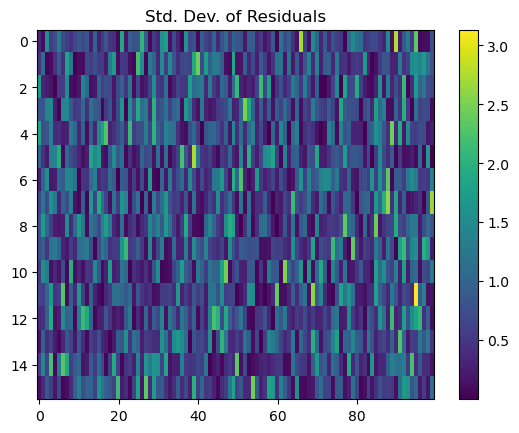

In [17]:
# This function will return a JAXArray of the same shape as Y
# but with outliers replaced with interpolated values
Y_clean = gp.sigma_clip(p_opt, # Make sure to perform sigma clipping using a good fit to the data
                        Y,     # Observations JAXArray
                        5.     # Significance level in standard deviations to clip at
                       )

For MCMC tuning with large numbers of parameters, it can be very helpful to use the Laplace approximation to select a good choice of tuning matrix or "mass matrix" for No U-Turn Sampling (NUTS). This can often return quite accurate approximations of the covariance matrix of the posterior - especially when most of the parameters are well constrained.

If outliers were clipped then optimisation may need to be ran again on the cleaned data before running this step as the Laplace approximation should be performed at the maximum of the posterior. Also note that we use the ``gp.laplace_approx_with_bounds`` method instead of ``gp.laplace_approx`` because we have bounds on some of our parameters which means ``NumPyro`` will perform a transformation on these parameters we would like our Laplace approximation to take account of. See the ``gp.laplace_approx_with_bounds`` documentation for more details.

In [18]:
# Returns the covariance matrix returned by the Laplace approximation
# Also returns a list of parameters which is the order the array is in
# This matches the way jax.flatten_util.ravel_pytree will sort the parameter PyTree into
cov_mat, ordered_param_list = gp.laplace_approx_with_bounds(
    p_opt,               # Make sure to use best-fit values
    Y_clean,             # The observations being fit
    param_bounds,        # Specify the same bounds that will be used for the MCMC
    fixed_vars = ["P"],  # Make sure to specify fixed parameters as otherwise they are marginalised over
    return_array = True, # May optionally return a nested PyTree if set to False which can be more readable
    regularise = True,   # Often necessary to regularise values that return negative covariance
    large = False,       # Setting this to True is more memory efficient which may be needed for large data sets
)

# This function will output information on what regularisation has been performed
# And will mention if there are remaining negative values along the diagonal of the covariance matrix
# It does not however check if the covariance matrix is invertible

No regularisation needed to remove negative values along diagonal of covariance matrix.


Build our model again using the same parameters being varied and sample all parameters using NUTS with ``NumPyro``

In [19]:
from numpyro.infer import MCMC, NUTS
from jax import random

# NumPyro makes use of the jax.random module to handle randomness
rng_key, rng_key_predict = random.split(random.PRNGKey(0))

# Define the sampler we will use
nuts_step = NUTS(transit_model, # Our transit model specified earlier
                   init_strategy = init_to_value(values = p_opt), # Often works well to initialise near best-fit values
                   inverse_mass_matrix = cov_mat, # Inverse mass matrix is the same as the tuning covariance matrix
                   adapt_mass_matrix=False, # Often Laplace approximation works better than trying to tune many parameters
                   dense_mass = True,       # Need a dense mass matrix to account for correlations between parameters
                   regularize_mass_matrix = False, # Mass matrix should already be regularised
                  )

mcmc = MCMC(
    nuts_step,         # Sampler to use
    num_warmup=1000,   # Number of warm-up steps
    num_samples=1000,  # Number of samples post warm-up
    num_chains=2,      # Number of chains to run
)

# Run inference with given random seed and any arguments to the NumPyro model
mcmc.run(rng_key, Y)

# Generate an arviz inference data object from MCMC chains
idata = az.from_numpyro(mcmc)

# Saves the inference object
#idata.to_json("MCMC_chains.json");

/var/folders/lp/chmp1tb92f5_x_wdckqwk34c0000gn/T/ipykernel_88060/2518427083.py:16: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(
sample: 100%|██████████████████████████████████████████████████████| 2000/2000 [01:03<00:00, 31.57it/s, 7 steps of size 4.83e-01. acc. prob=0.82]


Print a summary of the samples using ``arviz``. Important values to look at for convergence are that the effective sample size of the bulk of the distribution (``ess_bulk``) and the tail of the distribution (``ess_tail``) are at least ~500-1000 and that the Gelman-Rubin ``r_hat`` statistic is less than ~1.01 for each parameter.

In [20]:
az.summary(idata, round_to = 4)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Foot[0],1.0001,0.0002,0.9997,1.0004,0.0000,0.0000,2581.6047,1395.0689,1.0002
Foot[1],0.9999,0.0002,0.9996,1.0002,0.0000,0.0000,2603.4026,1483.0628,1.0003
Foot[2],0.9999,0.0002,0.9996,1.0002,0.0000,0.0000,2495.0413,1391.3152,1.0012
Foot[3],0.9998,0.0002,0.9995,1.0001,0.0000,0.0000,2633.3786,1464.7346,0.9991
Foot[4],0.9997,0.0002,0.9994,1.0000,0.0000,0.0000,2877.9637,1286.8689,1.0009
Foot[5],0.9998,0.0002,0.9995,1.0001,0.0000,0.0000,2773.5926,1274.7871,1.0008
Foot[6],0.9997,0.0002,0.9993,1.0000,0.0000,0.0000,2588.6742,1280.8638,0.9992
Foot[7],0.9997,0.0002,0.9994,1.0000,0.0000,0.0000,2743.9987,1121.2125,0.9994
Foot[8],0.9998,0.0002,0.9995,1.0002,0.0000,0.0000,2534.4695,1484.2407,0.9994
Foot[9],0.9999,0.0002,0.9995,1.0002,0.0000,0.0000,2450.6300,1287.3807,1.0001


The ``arviz.plot_trace`` function can be very useful for visualising the marginal posterior distributions of the different parameters as well as to examine the chains and diagnose any possible convergence issues.

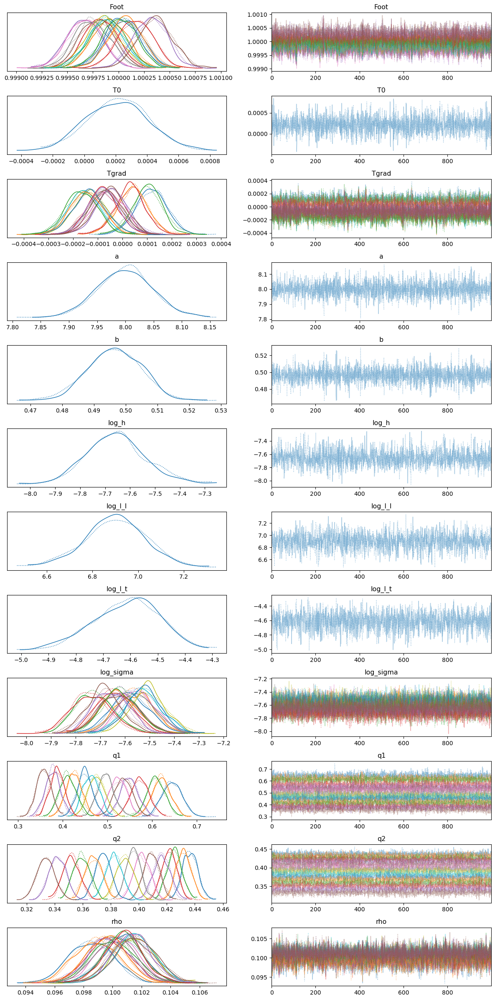

In [21]:
trace_plot = az.plot_trace(idata)
plt.tight_layout()

``corner`` is great for generating nice corner plots. Unfortunately when fitting many light curves the number of parameters can make visualising the full corner plot quite unwieldly but we can always just plot subsets of parameters instead.

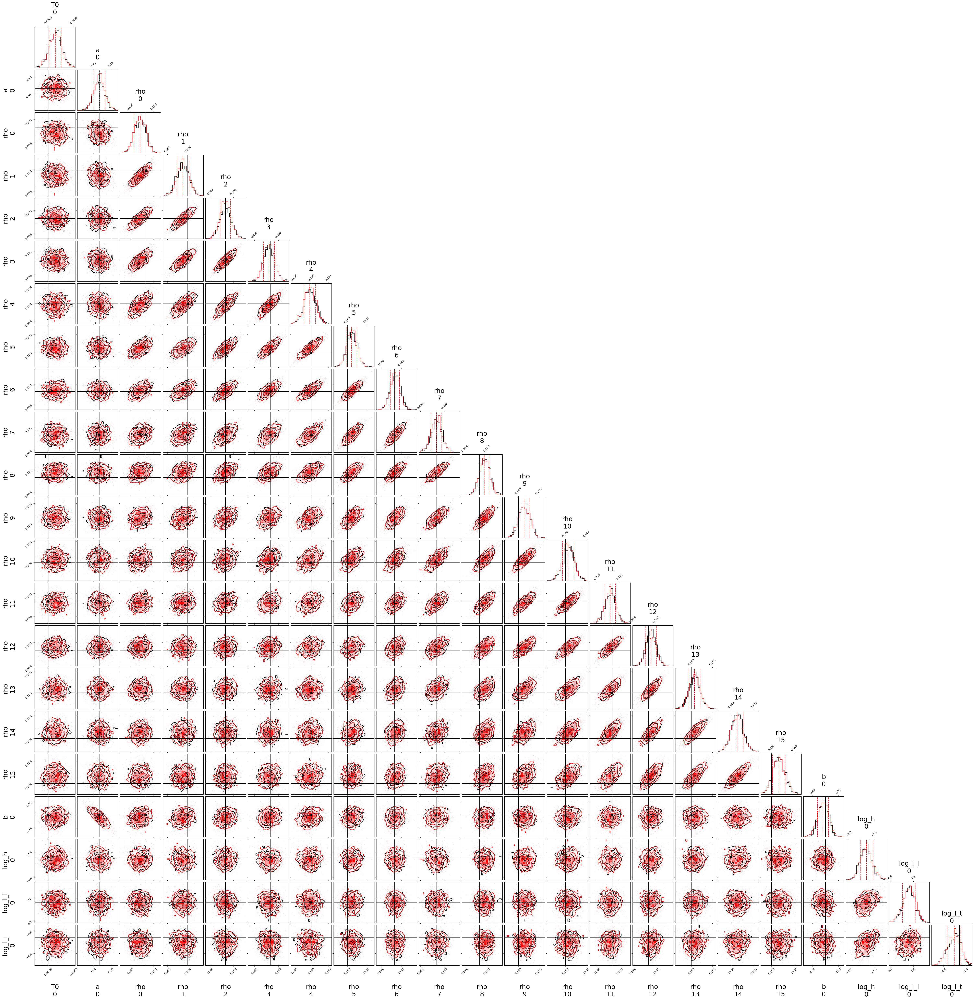

In [22]:
from corner import corner

# Select the parameters to include in the plot
params = ["T0", "a", "rho", "b", "log_h", "log_l_l", "log_l_t"]

# Plot each of the two chains separately
idata_corner1 = idata.sel(chain=[0])
idata_corner2 = idata.sel(chain=[1])

# Plot first chain
fig1 = corner(idata_corner1, smooth = 0.4, var_names = params)

# Plot second chain along with truth values
fig2 = corner(idata_corner2, quantiles=[0.16, 0.5, 0.84], title_fmt = None, title_kwargs={"fontsize": 23},
              label_kwargs={"fontsize": 23}, show_titles=True, smooth = 0.4, color = "r", fig = fig1,
              top_ticks = True, max_n_ticks = 2, labelpad = 0.16, var_names = params,
              truths = p_sim, truth_color = "k",
              )

If you want to examine the chains for any parameters you can use ``idata.posterior[param]`` to get an ``xarray.DataArray`` object and can use the ``to_numpy`` method to convert to a ``NumPy`` array. Below we retrieve the mean and covariance matrix of the radius ratio parameters and then visualise the transmission spectrum as well as the covariance matrix of the transmission spectrum.

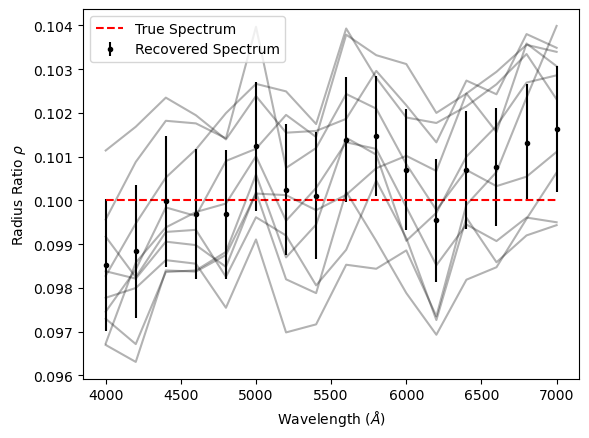

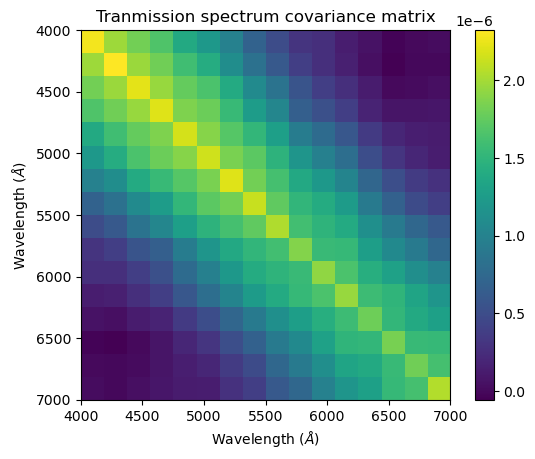

In [23]:
# NumPy array of MCMC samples of shape (N_chains, N_draws, N_l)
rho_chains = idata.posterior["rho"].to_numpy()

# Get the mean radius ratio values averaged over all chains and draws
rho_mean = rho_chains.mean((0, 1))

# Calculate the covariance matrix of each chain and average together
N_chains = rho_chains.shape[0]
rho_cov = jnp.zeros((N_l, N_l))
for i in range(N_chains):
    rho_cov += jnp.cov(rho_chains[0, :, :].T)
rho_cov /= N_chains

# Standard deviation given by sqrt of diagonal of covariance matrix
rho_std_dev = jnp.sqrt(jnp.diag(rho_cov))

# We can plot our recovered spectrum against the simulated true spectrum
plt.errorbar(x_l, rho_mean, yerr = rho_std_dev, fmt = 'k.', label = "Recovered Spectrum")
plt.plot(x_l, p_sim["rho"], 'r--', label = "True Spectrum")

# Select a few samples from the MCMC to help visualise the correlation between values
rho_draws = rho_chains[0, 0:1000:100, :].T
plt.plot(x_l, rho_draws, 'k-', alpha = 0.3)
plt.xlabel(r"Wavelength ($\AA$)")
plt.ylabel(r"Radius Ratio $\rho$")
plt.legend()
plt.show()

plt.title("Tranmission spectrum covariance matrix")
plt.imshow(rho_cov, extent = [x_l[0], x_l[-1], x_l[-1], x_l[0]])
plt.colorbar()
plt.xlabel(r"Wavelength ($\AA$)")
plt.ylabel(r"Wavelength ($\AA$)")
plt.show()

It can be hard to tell when there are significant correlations involved whether the recovered spectrum is actually consistent with the simulated spectrum. The reduced chi-squared statistic $\chi_r^2$ is useful for determining this. It is calculated using:

$$
\begin{equation}
    \chi_\mathrm{r}^2 = (\bar{\vec{\rho}}_\mathrm{ret} - \vec{\rho}_\mathrm{inj})^T \mathbf{K}_\mathrm{\vec{\rho}; ret}^{-1} (\bar{\vec{\rho}}_\mathrm{ret} - \vec{\rho}_\mathrm{inj}) / N_l,
\end{equation}
$$

Where $\bar{\vec{\rho}}_\mathrm{ret}$ is our retrieved mean transmission spectrum, $\vec{\rho}_\mathrm{inj}$ is the injected transmission spectrum and $\mathbf{K}_\mathrm{\vec{\rho}; ret}$ is our retrieved covariance matrix of the transmission spectrum

In [24]:
r = rho_mean - p_sim["rho"]
chi2_r = r.T @ jnp.linalg.inv(rho_cov) @ r / N_l

print("Reduced chi-squared value:", chi2_r)

# The reduced chi-squared distribution always has mean 1 but has different standard deviation
# Depending on the numbers of degrees of freedom
print("Distribution of reduced chi-squared: mu = 1, sigma =", jnp.sqrt(2/N_l))

Reduced chi-squared value: 1.2974745365563507
Distribution of reduced chi-squared: mu = 1, sigma = 0.3535533905932738
